#Import Required Libraries

In [2]:

import tensorflow as tf
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import (
    Input, ZeroPadding2D, Dense, Dropout, Activation,
    Conv2D, AveragePooling2D, GlobalAveragePooling2D,
    MaxPooling2D, BatchNormalization, Concatenate, Layer
)
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Model
import tensorflow.keras.backend as K
from sklearn.metrics import log_loss
import numpy as np
import os
import random
import cv2
import math
import seaborn as sns
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array
from sklearn.preprocessing import LabelBinarizer
from sklearn.model_selection import train_test_split
import shutil
from PIL import Image, ImageDraw, ImageFont
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)
import matplotlib.pyplot as plt


#Model Architecture

In [3]:
class Scale(Layer):
    """Learnable scale (gamma) and shift (beta) layer.
    Replicates the custom Scale layer from the original DenseNet-Keras repo."""

    def __init__(self, axis=-1, **kwargs):
        self.axis = axis
        super(Scale, self).__init__(**kwargs)

    def build(self, input_shape):
        dim = int(input_shape[self.axis])
        shape = (dim,)
        self.gamma = self.add_weight(
            name='gamma', shape=shape,
            initializer='ones', trainable=True
        )
        self.beta = self.add_weight(
            name='beta', shape=shape,
            initializer='zeros', trainable=True
        )
        super(Scale, self).build(input_shape)

    def call(self, x):
        input_shape = K.int_shape(x)
        broadcast_shape = [1] * len(input_shape)
        broadcast_shape[self.axis] = input_shape[self.axis]
        return (
            K.reshape(self.gamma, broadcast_shape) * x +
            K.reshape(self.beta,  broadcast_shape)
        )

    def get_config(self):
        config = {'axis': self.axis}
        base   = super(Scale, self).get_config()
        return dict(list(base.items()) + list(config.items()))

# It now loads tf.keras.applications.DenseNet121 with ImageNet-pretrained weights as
# a frozen feature extractor, and only trains a new classification head on top.
# ImageNet has no X-rays, but the early/mid conv layers learn general-purpose visual
# primitives (edges, textures, shapes) that transfer across image domains — this is
# Set freeze_base=False (after the head has trained for a few epochs) to unfreeze the
# base and fine-tune it end-to-end at a low learning rate.
def densenet121_model(img_rows, img_cols, color_type=3, nb_dense_block=4,
                      growth_rate=32, nb_filter=64, reduction=0.5,
                      dropout_rate=0.0, weight_decay=1e-4, num_classes=None,
                      freeze_base=True):
    """
    DenseNet121 with ImageNet-pretrained weights (transfer learning).

    # Returns
        A Keras model instance.
    """

    base_model = DenseNet121(
        include_top=False,
        weights='imagenet',
        input_shape=(img_rows, img_cols, color_type),
        pooling=None
    )
    base_model.trainable = not freeze_base  # frozen by default for the initial training pass

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.5)(x)
    x = Dense(num_classes)(x)
    predictions = Activation('softmax')(x)

    model = Model(inputs=base_model.input, outputs=predictions)

    # 'decay' kwarg is deprecated in Keras 3 (Colab TF 2.16+)
    # Use ExponentialDecay schedule instead
    lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=1e-3, decay_steps=10000, decay_rate=0.9
    )
    sgd = SGD(learning_rate=lr_schedule, momentum=0.9, nesterov=True)
    model.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])

    return model


In [1]:
def conv_block(x, stage, branch, nb_filter, dropout_rate=None):
    '''Apply BatchNorm, Relu, bottleneck 1x1 Conv2D, 3x3 Conv2D, and optional dropout'''

    # 1x1 Convolution (Bottleneck layer)
    inter_channel = nb_filter * 4
    x = BatchNormalization(axis=concat_axis)(x)
    x = Scale(axis=concat_axis)(x)
    x = Activation('relu')(x)
    # ── FIX 3: Convolution2D(f,1,1,bias=False) → Conv2D(f,(1,1),use_bias=False)
    x = Conv2D(inter_channel, (1, 1), use_bias=False)(x)

    if dropout_rate:
        x = Dropout(dropout_rate)(x)

    # 3x3 Convolution
    x = BatchNormalization(axis=concat_axis)(x)
    x = Scale(axis=concat_axis)(x)
    x = Activation('relu')(x)
    x = ZeroPadding2D((1, 1))(x)
    x = Conv2D(nb_filter, (3, 3), use_bias=False)(x)

    if dropout_rate:
        x = Dropout(dropout_rate)(x)

    return x


def transition_block(x, stage, nb_filter, dropout_rate=None):
    '''Apply BatchNorm, 1x1 Convolution, AveragePooling, optional compression, dropout'''

    x = BatchNormalization(axis=concat_axis)(x)
    x = Scale(axis=concat_axis)(x)
    x = Activation('relu')(x)
    x = Conv2D(int(nb_filter), (1, 1), use_bias=False)(x)

    if dropout_rate:
        x = Dropout(dropout_rate)(x)

    x = AveragePooling2D((2, 2), strides=(2, 2))(x)

    return x


def dense_block(x, stage, nb_layers, nb_filter, growth_rate,
                dropout_rate=None, grow_nb_filters=True):
    '''Build a dense_block where the output of each conv_block is fed to subsequent ones
    # Arguments
        x: input tensor
        stage: index for dense block
        nb_layers: the number of layers of conv_block to append to the model.
        nb_filter: number of filters
        growth_rate: growth rate
        grow_nb_filters: flag to decide to allow number of filters to grow
    '''

    concat_feat = x

    for i in range(nb_layers):
        branch = i + 1
        x = conv_block(concat_feat, stage, branch, growth_rate, dropout_rate)
        concat_feat = Concatenate(axis=concat_axis)([concat_feat, x])

        if grow_nb_filters:
            nb_filter += growth_rate

    return concat_feat, nb_filter


#Data Preprocessing

In [4]:
# ── COLAB: Mount Google Drive so your 'dataset' folder is accessible
from google.colab import drive
drive.mount('/content/drive')

# After mounting, set DATASET_PATH to wherever your dataset folder lives in Drive.
# Example: if your Drive has  MyDrive/dataset/  then use:
DATASET_PATH = '/content/drive/MyDrive/dataset'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# This function Splitting the data into 65% training, 20% validation, 15% testing
def split_dataset(source_dir, output_dir, train_ratio=0.65,
                  val_ratio=0.20, test_ratio=0.15):

    # Make sure the ratios add up to 1
    assert train_ratio + val_ratio + test_ratio == 1.0

    # Create train, validation and test folders
    for split in ['train', 'validation', 'test']:
        for class_name in os.listdir(source_dir):

            class_source = os.path.join(source_dir, class_name)

            if os.path.isdir(class_source):
                class_output = os.path.join(
                    output_dir, split, class_name
                )

                os.makedirs(class_output, exist_ok=True)

    # Process each class separately
    for class_name in os.listdir(source_dir):

        class_source = os.path.join(source_dir, class_name)

        if not os.path.isdir(class_source):
            continue

        images = [
            f for f in os.listdir(class_source)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        # Shuffle images
        random.seed(42)
        random.shuffle(images)

        total = len(images)

        train_end = int(total * train_ratio)
        val_end = train_end + int(total * val_ratio)

        train_images = images[:train_end]
        val_images = images[train_end:val_end]
        test_images = images[val_end:]

        # Copy images
        for image in train_images:
            shutil.copy2(
                os.path.join(class_source, image),
                os.path.join(output_dir, 'train', class_name, image)
            )

        for image in val_images:
            shutil.copy2(
                os.path.join(class_source, image),
                os.path.join(output_dir, 'validation', class_name, image)
            )

        for image in test_images:
            shutil.copy2(
                os.path.join(class_source, image),
                os.path.join(output_dir, 'test', class_name, image)
            )

        print(
            f"{class_name}: "
            f"Train={len(train_images)}, "
            f"Validation={len(val_images)}, "
            f"Test={len(test_images)}"
        )

In [ ]:
split_dataset(
    source_dir=DATASET_PATH,
    output_dir="/content/drive/MyDrive/split_dataset"
)

PNEUMONIA: Train=2055, Validation=632, Test=475
TURBERCULOSIS: Train=2054, Validation=632, Test=475
NORMAL: Train=2054, Validation=632, Test=475
COVID19: Train=2053, Validation=631, Test=475


#Image enhancement functions

In [5]:
# Contrast Limited Adaptive Histogram Equalization function
def clahe(image):
    # Convert to uint8
    image = image.astype(np.uint8)

    # Convert RGB to grayscale
    gray_image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Create CLAHE object
    clahe = cv2.createCLAHE(
        clipLimit=5.0,
        tileGridSize=(8, 8)
    )

    # Apply CLAHE
    clahe_image = clahe.apply(gray_image)

    # Convert grayscale back to RGB
    clahe_image = cv2.cvtColor(
        clahe_image,
        cv2.COLOR_GRAY2RGB
    )

    return clahe_image.astype(np.float32)

In [6]:
# Histogram Equalization function
def histogram_equalization(image):
    # Convert image from RGB to grayscale
    gray_image = cv2.cvtColor(image.astype(np.uint8), cv2.COLOR_RGB2GRAY)

    # Apply Histogram Equalization
    equalized_image = cv2.equalizeHist(gray_image)

    # Convert grayscale back to RGB (3 channels)
    equalized_image = cv2.cvtColor(equalized_image, cv2.COLOR_GRAY2RGB)

    return equalized_image.astype(np.float32)

## Data Visualization

In [6]:

# Visualize Original, Histogram Equalization, and CLAHE
# using the SAME randomly selected image

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
import os
import numpy as np


def view_random_image(target_dir, target_class):

    # Setup the target directory
    target_folder = os.path.join(target_dir, target_class)

    # Select ONE random image
    random_image = random.choice(os.listdir(target_folder))

    # Get the image path
    image_path = os.path.join(target_folder, random_image)

    # Read the image
    img = mpimg.imread(image_path)

    # Apply Histogram Equalization to the SAME image
    he_img = histogram_equalization(img)

    # Apply CLAHE to the SAME image
    clahe_img = clahe(img)



    # FIGURE 1: ORIGINAL IMAGE
    plt.figure(figsize=(6, 6))

    plt.imshow(img, cmap="gray")
    plt.title(f"Original - {target_class}", fontsize=14)
    plt.axis("off")

    plt.tight_layout()
    plt.show()


    # FIGURE 2: HISTOGRAM EQUALIZATION


    plt.figure(figsize=(6, 6))

    plt.imshow(he_img.astype(np.uint8), cmap="gray")
    plt.title(f"Histogram Equalization - {target_class}", fontsize=14)
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # FIGURE 3: CLAHE

    plt.figure(figsize=(6, 6))

    plt.imshow(clahe_img.astype(np.uint8), cmap="gray")
    plt.title(f"CLAHE - {target_class}", fontsize=14)
    plt.axis("off")

    plt.tight_layout()
    plt.show()


    # Print information
    print(f"Selected image: {random_image}")
    print(f"Original image shape: {img.shape}")
    print(f"Histogram Equalization image shape: {he_img.shape}")
    print(f"CLAHE image shape: {clahe_img.shape}")





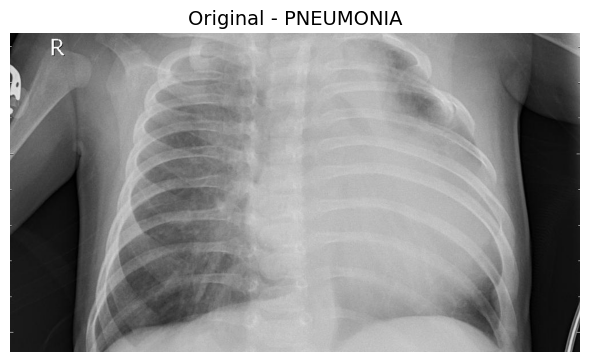

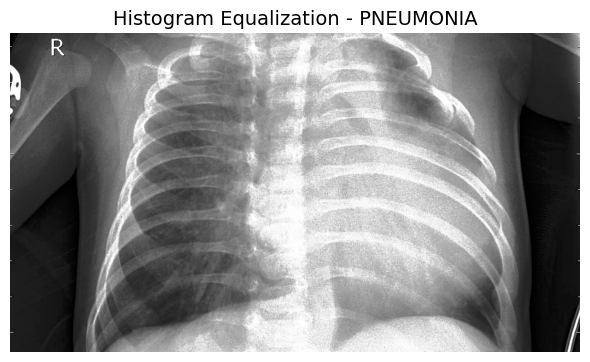

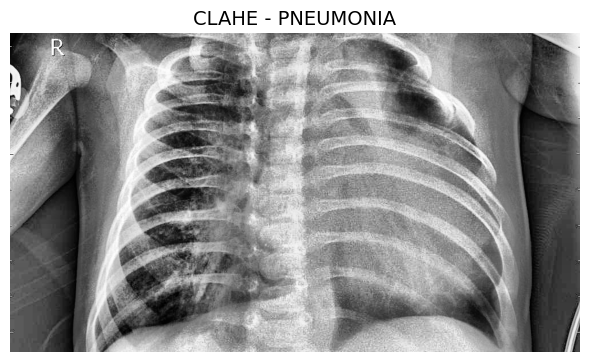

Selected image: PNEUMONIA(3936).jpg
Original image shape: (560, 1000, 3)
Histogram Equalization image shape: (560, 1000, 3)
CLAHE image shape: (560, 1000, 3)


In [7]:
view_random_image(target_dir="/content/drive/MyDrive/split_dataset/train/",target_class="PNEUMONIA")

# Implement your own load_data() module for your own dataset

In [7]:
def load_data(enhancement_function,batch_size=32):
    datagen = ImageDataGenerator(rescale=1./255,
                                 preprocessing_function=enhancement_function)

    train_gen = datagen.flow_from_directory(
        directory="/content/drive/MyDrive/split_dataset/train",
        target_size=(224, 224),
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=True,
        seed=42
    )

    val_gen = datagen.flow_from_directory(
        directory="/content/drive/MyDrive/split_dataset/validation",
        target_size=(224, 224),
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=False
    )

    test_gen = datagen.flow_from_directory(
        directory="/content/drive/MyDrive/split_dataset/test",
        target_size=(224, 224),
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=False
    )

    print('Classes found:', train_gen.class_indices)
    return train_gen, val_gen, test_gen


In [ ]:
# Experiment Intializer function
def run_experiments(enhancement_function=None):
    img_rows, img_cols = 224, 224  # Resolution of inputs
    channel     = 3
    num_classes = 4
    batch_size  = 32
    nb_epoch    = 30

    # ── load_data() now returns generators, not numpy arrays
    train_gen, val_gen ,test_gen= load_data(enhancement_function=enhancement_function, batch_size=batch_size)

    model = densenet121_model(
        img_rows=img_rows, img_cols=img_cols,
        color_type=channel, num_classes=num_classes
    )

    filepath   = "bestmodel.keras"  # ── COLAB FIX: Keras 3 prefers .keras over .hdf5
    checkpoint = ModelCheckpoint(
        filepath, monitor='val_accuracy',
        verbose=1, save_best_only=True, mode='max'
    )
    callbacks_list = [checkpoint]

    # ── Generators replace X_train/Y_train and X_valid/Y_valid
    history = model.fit(
        train_gen,
        epochs=nb_epoch,
        verbose=1,
        validation_data=val_gen,
        callbacks=callbacks_list,
    )

    model.save(f"/content/drive/MyDrive/{model}.keras")

    predictions_valid = model.predict(val_gen, verbose=1)
    score = log_loss(val_gen.classes, predictions_valid)
    return history, model , train_gen, val_gen ,test_gen

In [ ]:
#This is the function for the loss curve to check whether the model is overfitting during training
def loss_curve(history):

  # Evaluating Accuracy and Loss of the model
  %matplotlib inline


  acc     = history.history['accuracy']
  val_acc = history.history['val_accuracy']
  loss    = history.history['loss']
  val_loss= history.history['val_loss']

  epochs = range(len(acc))

  import matplotlib.pyplot as plt

  # Plot training and validation accuracy per epoch
  plt.plot(epochs, acc,     'b', label='Training Accuracy')
  plt.plot(epochs, val_acc, 'r', label='Validation Accuracy')
  plt.legend()
  plt.figure()

  # Plot training and validation loss per epoch
  plt.plot(epochs, loss,     'b', label='Training Loss')
  plt.plot(epochs, val_loss, 'r', label='Validation Loss')
  plt.legend()
  plt.show()

# Model Training

## Experiment 1: None:

*In this experiment we will train the model but we will not apply and image enhancement methods, evaluate it on the test  



In [ ]:
# Run the model
history_1, model_1 , train_gen_1, val_gen_1 ,test_gen_1= run_experiments(enhancement_function=None)

Found 8216 images belonging to 4 classes.
Found 2527 images belonging to 4 classes.
Found 1900 images belonging to 4 classes.
Classes found: {'COVID19': 0, 'NORMAL': 1, 'PNEUMONIA': 2, 'TURBERCULOSIS': 3}
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 432ms/step - accuracy: 0.5735 - loss: 1.0333
Epoch 1: val_accuracy improved from None to 0.88207, saving model to bestmodel.keras

Epoch 1: finished saving model to bestmodel.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 199s 651ms/step - accuracy: 0.7024 - loss: 0.7260 - val_accuracy: 0.8821 - val_loss: 0.3577
Epoch 2/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 0.8142 - loss: 0.4752
Epoch 2: val_accuracy improved from 0.88207 to 0.90305, saving model to bestmodel.keras

Epoch 2: finished saving model to bestmodel.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 109s 424ms/step - accuracy: 0.8133 - loss: 0.4727 - val_accuracy: 0.9030 - val_loss: 0.3108
Epoch 3/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/st

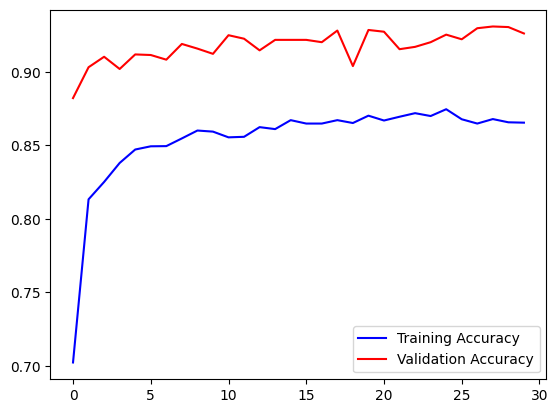

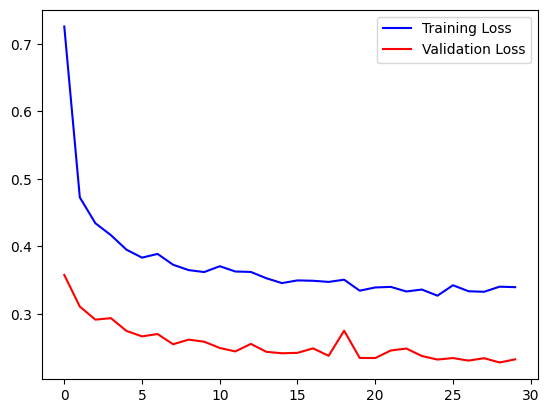

In [ ]:
#Plot the loss curve of the experiments
loss_curve(history_1)

## Experiment2:histogram_equalization

In [ ]:
# Run the model
history_2, model_2 ,train_gen_2, val_gen_2 ,test_gen_2= run_experiments(enhancement_function=histogram_equalization)

Found 8216 images belonging to 4 classes.
Found 2527 images belonging to 4 classes.
Found 1900 images belonging to 4 classes.
Classes found: {'COVID19': 0, 'NORMAL': 1, 'PNEUMONIA': 2, 'TURBERCULOSIS': 3}
Epoch 1/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 371ms/step - accuracy: 0.5799 - loss: 1.0359
Epoch 1: val_accuracy improved from None to 0.87297, saving model to bestmodel.keras

Epoch 1: finished saving model to bestmodel.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 169s 560ms/step - accuracy: 0.6947 - loss: 0.7366 - val_accuracy: 0.8730 - val_loss: 0.3731
Epoch 2/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step - accuracy: 0.7980 - loss: 0.4869
Epoch 2: val_accuracy improved from 0.87297 to 0.88643, saving model to bestmodel.keras

Epoch 2: finished saving model to bestmodel.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 109s 424ms/step - accuracy: 0.8038 - loss: 0.4773 - val_accuracy: 0.8864 - val_loss: 0.3234
Epoch 3/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 0.8144 - loss: 0.4539
Epoch 3: val_a

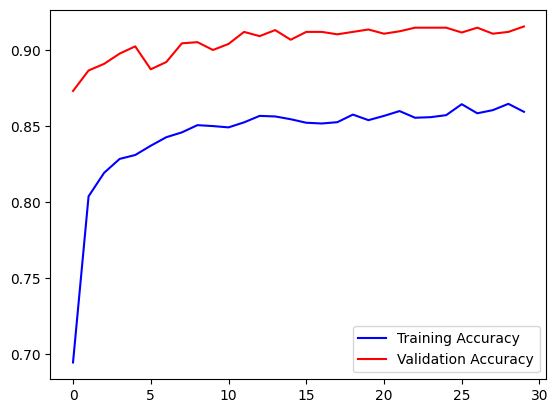

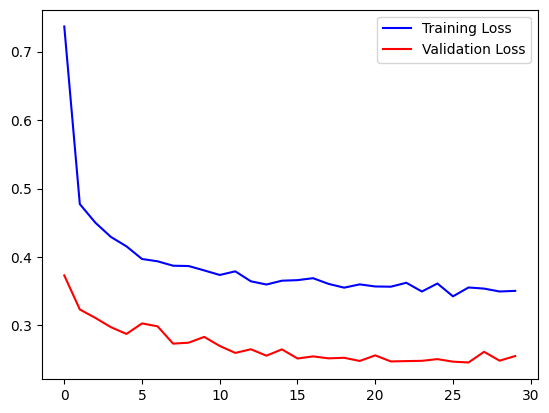

In [ ]:
#Plot the loss curve of the experiments
loss_curve(history_2)

## Experiment 3:clahe enhancement

In [ ]:
# Run the model
history_3, model_3 ,train_gen_3, val_gen_3 ,test_gen_3= run_experiments(enhancement_function=clahe_enhancement)

Found 8216 images belonging to 4 classes.
Found 2527 images belonging to 4 classes.
Found 1900 images belonging to 4 classes.
Classes found: {'COVID19': 0, 'NORMAL': 1, 'PNEUMONIA': 2, 'TURBERCULOSIS': 3}
Epoch 1/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - accuracy: 0.5925 - loss: 1.0482
Epoch 1: val_accuracy improved from None to 0.88880, saving model to bestmodel.keras

Epoch 1: finished saving model to bestmodel.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 175s 582ms/step - accuracy: 0.7069 - loss: 0.7288 - val_accuracy: 0.8888 - val_loss: 0.3308
Epoch 2/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - accuracy: 0.8171 - loss: 0.4609
Epoch 2: val_accuracy improved from 0.88880 to 0.89949, saving model to bestmodel.keras

Epoch 2: finished saving model to bestmodel.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 115s 448ms/step - accuracy: 0.8158 - loss: 0.4600 - val_accuracy: 0.8995 - val_loss: 0.2943
Epoch 3/30
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - accuracy: 0.8255 - loss: 0.4379
Epoch 3: val_a

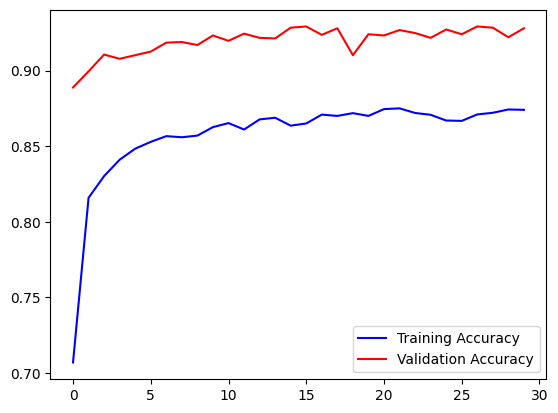

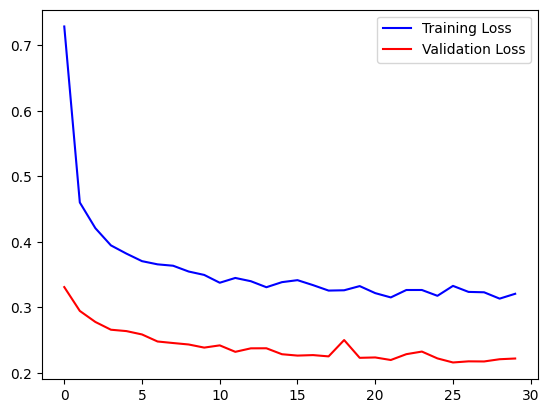

In [ ]:
#Plot the loss curve of the experiments
loss_curve(history_3)

#Evaluation Metrics and Incorrectly and correctly predicted samples

In [8]:

import matplotlib.pyplot as plt
import random
import os
import cv2
import numpy as np

def correctly_predicted_samples(val_gen, ypred, ytest, accurateindex):

    label = ['COVID19', 'NORMAL', 'PNEUMONIA', 'TURBERCULOSIS']

    # Randomly select 9 correctly classified images
    imidx = random.sample(accurateindex, k=min(3, len(accurateindex)))

    nrows = 1
    ncols = 3

    fig, ax = plt.subplots(nrows, ncols, figsize=(15, 5),squeeze=False)

    val_filepaths = val_gen.filepaths

    for n, idx in enumerate(imidx):

        row = n // ncols
        col = n % ncols

        # Load image
        img = cv2.imread(val_filepaths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (224, 224))

        # Extract filename
        filename = os.path.basename(val_filepaths[idx])

        # Display image
        ax[row, col].imshow(img)

        ax[row, col].set_title(
            "Filename: {}\nPredicted: {}\nTrue: {}".format(
                filename,
                label[np.argmax(ypred[idx])],
                label[ytest[idx]]
            ),
            fontsize=9
        )

        ax[row, col].axis('off')

    # Hide unused subplots if fewer than 9 images are available
    for n in range(len(imidx), nrows * ncols):
        ax[n // ncols, n % ncols].axis('off')

    plt.tight_layout()
    plt.show()


In [9]:
def Incorrectly_predicted_samples(val_gen, ypred, ytest, wrongindex):

    label = ['COVID19', 'NORMAL', 'PNEUMONIA', 'TURBERCULOSIS']

    # Randomly select 9 incorrectly classified images
    imidx = random.sample(wrongindex, k=min(3, len(wrongindex)))

    nrows = 1
    ncols = 3

    fig, ax = plt.subplots(nrows, ncols, figsize=(15, 5),squeeze=False)

    val_filepaths = val_gen.filepaths

    for n, idx in enumerate(imidx):

        row = n // ncols
        col = n % ncols

        # Load image
        img = cv2.imread(val_filepaths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (224, 224))

        # Extract filename
        filename = os.path.basename(val_filepaths[idx])

        # Display image
        ax[row, col].imshow(img)

        ax[row, col].set_title(
            "Filename: {}\nPredicted: {}\nTrue: {}".format(
                filename,
                label[np.argmax(ypred[idx])],
                label[ytest[idx]]
            ),
            fontsize=9
        )

        ax[row, col].axis('off')

    # Hide unused subplots if fewer than 9 images are available
    for n in range(len(imidx), nrows * ncols):
        ax[n // ncols, n % ncols].axis('off')

    plt.tight_layout()
    plt.show()

In [10]:
#Evaluation metrics which is precision,recall,accuracy, f1-score, and confusion matrix
def evaluation_matrix(ytest, ypred, experiment_name, output_dir="evaluation_results"):
    # Create folder for evaluation results
    os.makedirs(output_dir, exist_ok=True)

    # Class labels
    labels = [
        'COVID19',
        'NORMAL',
        'PNEUMONIA',
        'TURBERCULOSIS'
    ]


    # True and predicted labels
    y_true = ytest
    y_pred = np.argmax(ypred, axis=1)



    # Confusion Matrix

    cm = confusion_matrix(y_true, y_pred)

    # Per-class Precision, Recall and F1-score

    precision = precision_score(
        y_true,
        y_pred,
        average=None,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average=None,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average=None,
        zero_division=0
    )



    # Per-class Accuracy
    total_samples = len(y_true)

    per_class_accuracy = []

    for i in range(len(labels)):

        tp = cm[i, i]

        fn = cm[i, :].sum() - tp

        fp = cm[:, i].sum() - tp

        tn = total_samples - tp - fn - fp

        accuracy = (tp + tn) / total_samples

        per_class_accuracy.append(accuracy)

    per_class_accuracy = np.array(per_class_accuracy)



    # Overall Accuracy
    overall_accuracy = accuracy_score(
        y_true,
        y_pred
    )
    # PRINT RESULTS

    print("\n" + "=" * 70)
    print(f"EVALUATION RESULTS — {experiment_name}")
    print("=" * 70)

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=labels,
            zero_division=0
        )
    )

    print(
        f"Overall Accuracy: {overall_accuracy * 100:.2f}%"
    )

    # IMAGE 1 — CONFUSION MATRIX
    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        linewidths=0.5
    )

    plt.xlabel(
        'Predicted Label',
        fontsize=12
    )

    plt.ylabel(
        'True Label',
        fontsize=12
    )

    plt.title(
        f'Confusion Matrix — {experiment_name}',
        fontsize=14,
        fontweight='bold'
    )

    plt.xticks(rotation=30)
    plt.yticks(rotation=0)

    plt.tight_layout()


    # Create filename
    confusion_path = os.path.join(
        output_dir,
        f"{experiment_name}_confusion_matrix.png"
    )


    # Save image
    plt.savefig(
        confusion_path,
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

    plt.close()

    return {
        "experiment": experiment_name,
        "accuracy": overall_accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "confusion_matrix": cm,
        "confusion_matrix_path": confusion_path
    }

In [11]:
#This is the function for the loss curve to check whether the model is overfitting during training
def pred_on_test(test_gen, model, model_name, enhancement_function=None):

    # Ensure predictions follow the original file order
    test_gen.shuffle = False
    test_gen.reset()

    xtest = test_gen
    ytest = test_gen.classes

    # Make predictions without displaying the progress bar
    ypred = model.predict(test_gen, verbose=0)

    test_gen.reset()

    # Verify prediction and label counts
    if len(ypred) != len(ytest):
        raise ValueError("Mismatch between predictions and actual labels.")

    if len(test_gen.filepaths) != len(ytest):
        raise ValueError("Number of image paths and labels do not match.")

    total = 0
    accurate = 0

    accurateindex = []
    wrongindex = []

    # Google Drive destination
    output_dir = os.path.join(
        '/content/drive/MyDrive/Test_Prediction_Results',
        str(model_name)
    )

    # Clear previous results for this model only
    if os.path.exists(output_dir):
        shutil.rmtree(output_dir)

    # Get class names
    class_indices = test_gen.class_indices
    class_names = {v: k for k, v in class_indices.items()}

    # Track saved images per class
    saved_counts = {
        cls: {
            'correctly-predicted-images': 0,
            'incorrectly-predicted-images': 0
        }
        for cls in class_indices
    }

    # Process each test image
    for i in range(len(ypred)):

        # Actual and predicted labels
        true_label = ytest[i]
        predicted_label = np.argmax(ypred[i])

        true_class = class_names[true_label]
        predicted_class = class_names[predicted_label]

        # Get corresponding image path
        image_path = test_gen.filepaths[i]

        # Determine whether prediction is correct
        if predicted_label == true_label:

            accurate += 1
            accurateindex.append(i)

            folder_name = 'correctly-predicted-images'

        else:

            wrongindex.append(i)

            folder_name = 'incorrectly-predicted-images'

        # Create destination folder using actual class
        destination_folder = os.path.join(
            output_dir,
            true_class,
            folder_name
        )

        os.makedirs(destination_folder, exist_ok=True)

        # Load original image as RGB
        img = np.array(load_img(image_path))

        # Apply enhancement if supplied
        if enhancement_function is not None:

            # Enhancement function handles grayscale conversion
            img_to_save = enhancement_function(img)

            # Convert enhanced image to uint8 for saving
            img_to_save = np.asarray(img_to_save)

            if img_to_save.dtype != np.uint8:
                img_to_save = np.clip(img_to_save, 0, 255).astype(np.uint8)

            # Create PIL image
            enhanced_image = Image.fromarray(img_to_save)

        else:

            # Keep original image without enhancement
            enhanced_image = Image.fromarray(img)

        # Ensure image is in RGB or grayscale format
        if enhanced_image.mode not in ('RGB', 'L'):
            enhanced_image = enhanced_image.convert('RGB')

        # Prepare prediction text
        label_text = (
            f"Predicted: {predicted_class}, True: {true_class}"
        )

        # Set font
        try:
            font = ImageFont.truetype("DejaVuSans.ttf", 12)
        except OSError:
            font = ImageFont.load_default()

        # Calculate text area
        temp_draw = ImageDraw.Draw(enhanced_image)
        text_bbox = temp_draw.textbbox((0, 0), label_text, font=font)

        text_width = text_bbox[2] - text_bbox[0]
        text_height = text_bbox[3] - text_bbox[1]

        # Add a small white space above the image
        padding = 8
        canvas = Image.new(
            enhanced_image.mode,
            (enhanced_image.width, enhanced_image.height + text_height + padding * 2),
            color=255
        )

        # Place the enhanced image below the text area
        canvas.paste(
            enhanced_image,
            (0, text_height + padding * 2)
        )

        # Draw prediction text
        draw = ImageDraw.Draw(canvas)

        text_x = max(0, (canvas.width - text_width) // 2)

        draw.text(
            (text_x, padding),
            label_text,
            fill=0,
            font=font
        )

        # Save annotated image
        save_path = os.path.join(
            destination_folder,
            os.path.splitext(os.path.basename(image_path))[0] + '.png'
        )

        canvas.save(save_path)

        # Count successfully saved image
        if os.path.exists(save_path):
            saved_counts[true_class][folder_name] += 1

        total += 1

    # Calculate accuracy
    accuracy = (accurate / total * 100) if total > 0 else 0

    print('\nMODEL RESULTS')

    print('Model:', model_name)
    print('Total-test-data:', total)
    print('Accurately-predicted-data:', accurate)
    print('Wrongly-predicted-data:', len(wrongindex))
    print('Accuracy:', round(accuracy, 3), '%')

    print('\nGOOGLE DRIVE SAVED IMAGES')

    for cls, counts in saved_counts.items():

        print(f'\n{cls}:')
        print('Correctly predicted:',
              counts['correctly-predicted-images'])
        print('Incorrectly predicted:',
              counts['incorrectly-predicted-images'])

    total_saved = sum(
        sum(counts.values())
        for counts in saved_counts.values()
    )

    print('\nTotal images saved:', total_saved)

    if total_saved == total:
        print('SUCCESS: All images were saved.')
    else:
        print('WARNING: Saved image count does not match test count.')

    print('\nSaved in:', output_dir)

    return xtest, ytest, ypred, accurateindex, wrongindex


# Model Testing

In [12]:
from tensorflow.keras.models import load_model

## 1 Experiment:None

In [13]:
# Load the saved model during training
model_1 = tf.keras.models.load_model("/content/drive/MyDrive/<Functional name=functional, built=True>.keras")

In [15]:
train_gen_1, val_gen_1, test_gen_1 = load_data(
    enhancement_function=None,
    batch_size=32
)

Found 8216 images belonging to 4 classes.
Found 2527 images belonging to 4 classes.
Found 1900 images belonging to 4 classes.
Classes found: {'COVID19': 0, 'NORMAL': 1, 'PNEUMONIA': 2, 'TURBERCULOSIS': 3}


In [16]:
xtest_1,ytest_1,ypred_1,accurateindex,wrongindex=pred_on_test(test_gen_1,model_1,'None')


MODEL RESULTS
Model: None
Total-test-data: 1900
Accurately-predicted-data: 1730
Wrongly-predicted-data: 170
Accuracy: 91.053 %

GOOGLE DRIVE SAVED IMAGES

COVID19:
Correctly predicted: 439
Incorrectly predicted: 36

NORMAL:
Correctly predicted: 451
Incorrectly predicted: 24

PNEUMONIA:
Correctly predicted: 424
Incorrectly predicted: 51

TURBERCULOSIS:
Correctly predicted: 416
Incorrectly predicted: 59

Total images saved: 1900
SUCCESS: All images were saved.

Saved in: /content/drive/MyDrive/Test_Prediction_Results/None



EVALUATION RESULTS — None
               precision    recall  f1-score   support

      COVID19       0.87      0.92      0.90       475
       NORMAL       0.91      0.95      0.93       475
    PNEUMONIA       0.94      0.89      0.92       475
TURBERCULOSIS       0.93      0.88      0.90       475

     accuracy                           0.91      1900
    macro avg       0.91      0.91      0.91      1900
 weighted avg       0.91      0.91      0.91      1900

Overall Accuracy: 91.05%


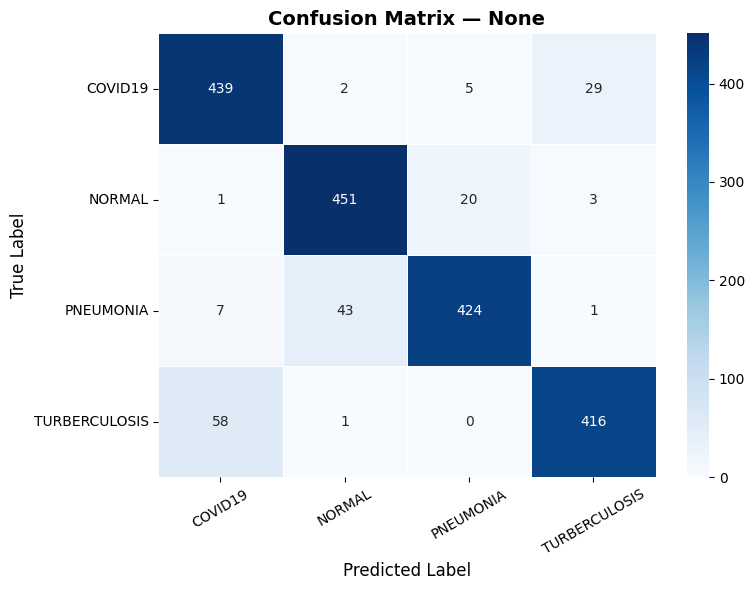

In [20]:
#Evalution Metrix
model_1_evaluation_metrix=evaluation_matrix(ytest_1, ypred_1, experiment_name="None",output_dir="/content/drive/MyDrive/evaluation_results")

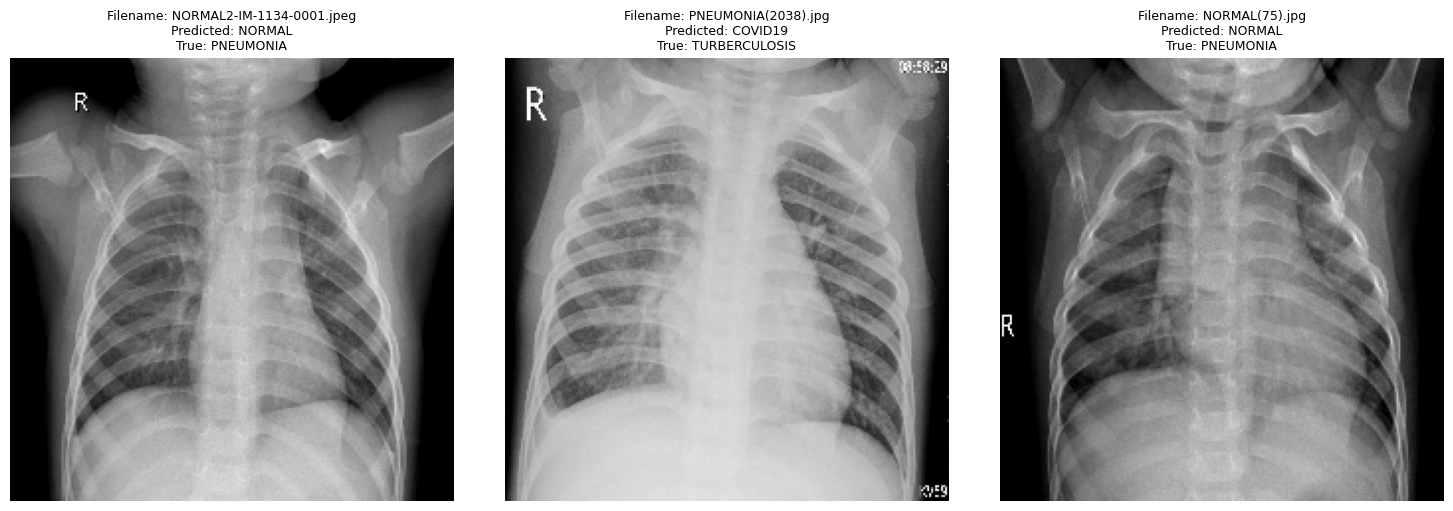

In [42]:
Incorrectly_predicted_samples(val_gen_1,ypred_1,ytest_1,wrongindex)

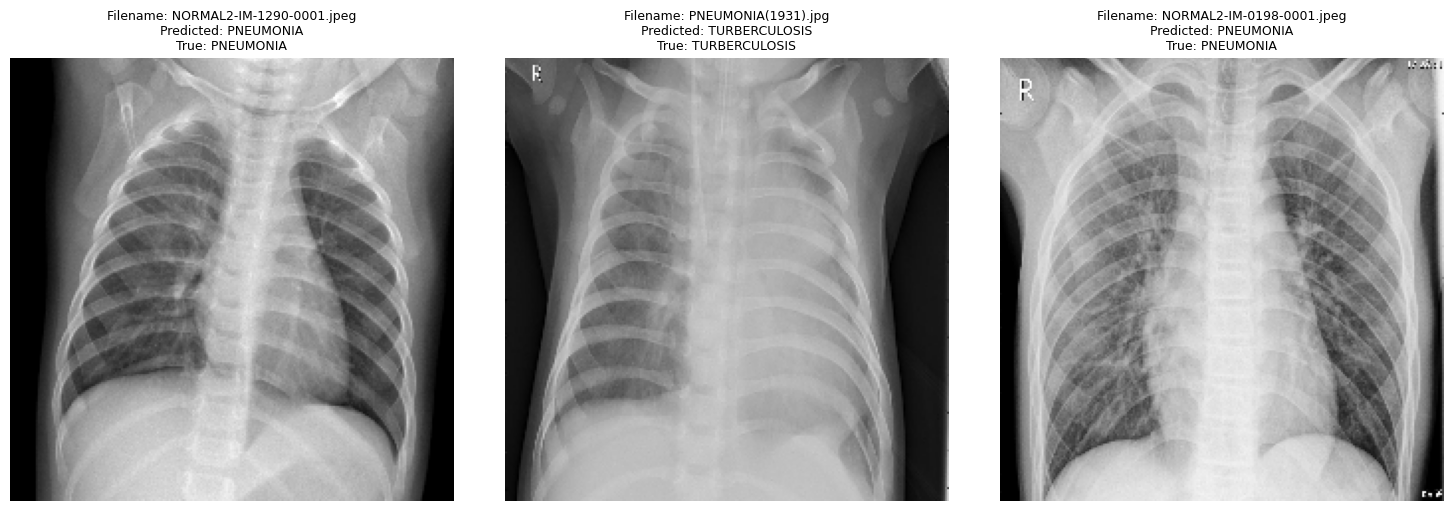

In [43]:
#Incorrectly predicted sample of images
correctly_predicted_samples(val_gen_1,ypred_1,ytest_1,accurateindex)

## 2 Experiment: Histogram_Equalization

In [13]:
model_2= tf.keras.models.load_model("/content/drive/MyDrive/<Functional name=functional_1, built=True>.keras")

In [14]:
train_gen_2, val_gen_2, test_gen_2 = load_data(
    enhancement_function=histogram_equalization,
    batch_size=32
)

Found 8216 images belonging to 4 classes.
Found 2527 images belonging to 4 classes.
Found 1900 images belonging to 4 classes.
Classes found: {'COVID19': 0, 'NORMAL': 1, 'PNEUMONIA': 2, 'TURBERCULOSIS': 3}


In [15]:
xtest_2,ytest_2,ypred_2,accurateindex,wrongindex=pred_on_test(test_gen_2,model_2,'Histogram_equalization',enhancement_function=histogram_equalization)


MODEL RESULTS
Model: Histogram_equalization
Total-test-data: 1900
Accurately-predicted-data: 1720
Wrongly-predicted-data: 180
Accuracy: 90.526 %

GOOGLE DRIVE SAVED IMAGES

COVID19:
Correctly predicted: 435
Incorrectly predicted: 40

NORMAL:
Correctly predicted: 456
Incorrectly predicted: 19

PNEUMONIA:
Correctly predicted: 402
Incorrectly predicted: 73

TURBERCULOSIS:
Correctly predicted: 427
Incorrectly predicted: 48

Total images saved: 1900
SUCCESS: All images were saved.

Saved in: /content/drive/MyDrive/Test_Prediction_Results/Histogram_equalization



EVALUATION RESULTS — Histogram Equalization
               precision    recall  f1-score   support

      COVID19       0.89      0.92      0.90       475
       NORMAL       0.87      0.96      0.91       475
    PNEUMONIA       0.98      0.85      0.91       475
TURBERCULOSIS       0.90      0.90      0.90       475

     accuracy                           0.91      1900
    macro avg       0.91      0.91      0.91      1900
 weighted avg       0.91      0.91      0.91      1900

Overall Accuracy: 90.53%


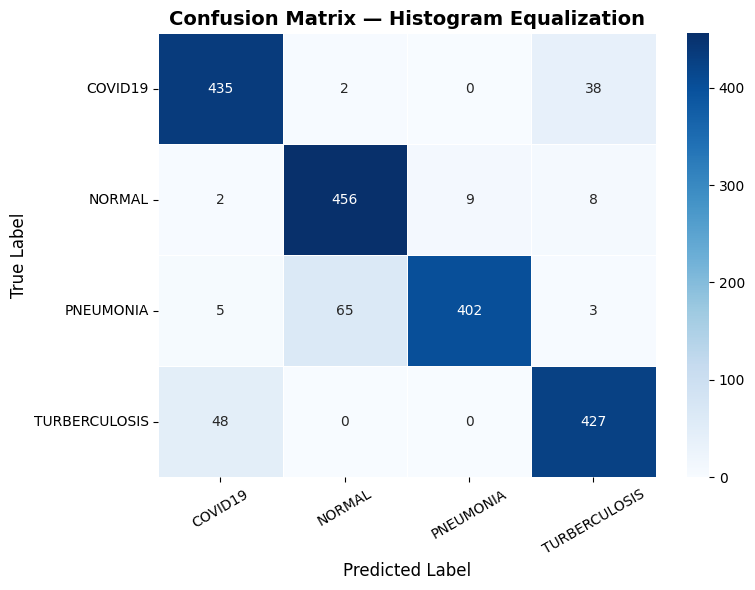

In [16]:
#Evalution Metrix
#Evalution Metrix
model_2_evaluation_metrix=evaluation_matrix(ytest_2, ypred_2, experiment_name="Histogram Equalization",output_dir="/content/drive/MyDrive/evaluation_results")

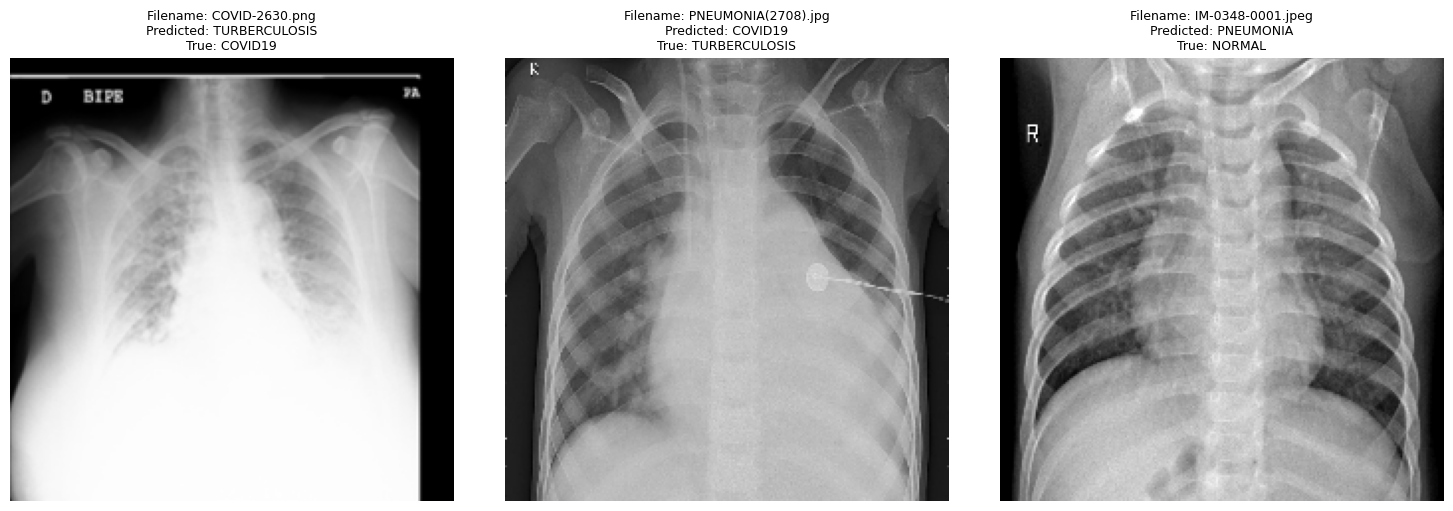

In [17]:
#correctly predicted samples of images
Incorrectly_predicted_samples(val_gen_2,ypred_2,ytest_2,wrongindex)

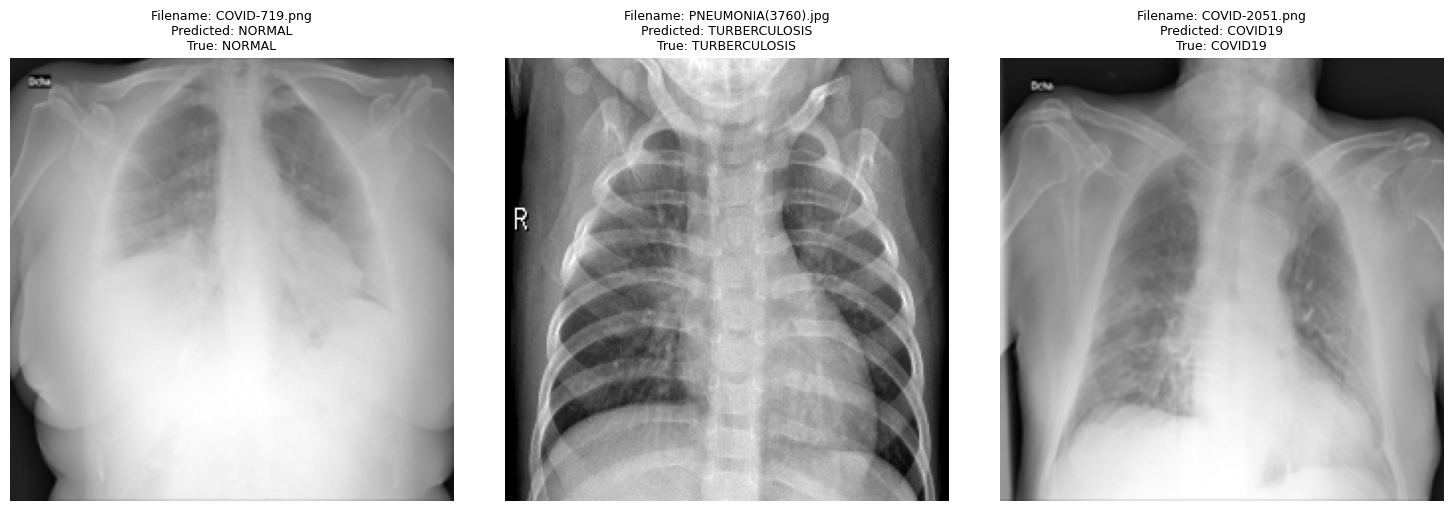

In [18]:
#correctly predicted sample of images
correctly_predicted_samples(val_gen_2,ypred_2,ytest_2,accurateindex)

### Experiment 3: CLAHE

In [19]:
model_3= tf.keras.models.load_model("/content/drive/MyDrive/<Functional name=functional_2, built=True>.keras")

In [20]:
train_gen_3, val_gen_3, test_gen_3 = load_data(
    enhancement_function=clahe,
    batch_size=32
)

Found 8216 images belonging to 4 classes.
Found 2527 images belonging to 4 classes.
Found 1900 images belonging to 4 classes.
Classes found: {'COVID19': 0, 'NORMAL': 1, 'PNEUMONIA': 2, 'TURBERCULOSIS': 3}


In [21]:
xtest_3,ytest_3,ypred_3,accurateindex,wrongindex=pred_on_test(test_gen_3,model_3,'CLAHE',enhancement_function=clahe)


MODEL RESULTS
Model: CLAHE
Total-test-data: 1900
Accurately-predicted-data: 1740
Wrongly-predicted-data: 160
Accuracy: 91.579 %

GOOGLE DRIVE SAVED IMAGES

COVID19:
Correctly predicted: 409
Incorrectly predicted: 66

NORMAL:
Correctly predicted: 443
Incorrectly predicted: 32

PNEUMONIA:
Correctly predicted: 440
Incorrectly predicted: 35

TURBERCULOSIS:
Correctly predicted: 448
Incorrectly predicted: 27

Total images saved: 1900
SUCCESS: All images were saved.

Saved in: /content/drive/MyDrive/Test_Prediction_Results/CLAHE



EVALUATION RESULTS — clahe
               precision    recall  f1-score   support

      COVID19       0.93      0.86      0.89       475
       NORMAL       0.93      0.93      0.93       475
    PNEUMONIA       0.94      0.93      0.93       475
TURBERCULOSIS       0.87      0.94      0.91       475

     accuracy                           0.92      1900
    macro avg       0.92      0.92      0.92      1900
 weighted avg       0.92      0.92      0.92      1900

Overall Accuracy: 91.58%


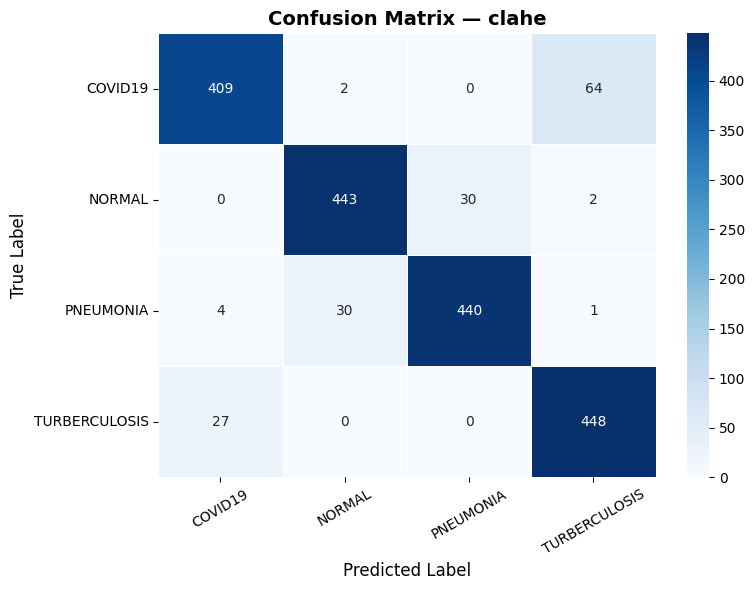

In [22]:
#Evaluation Metrix
model_3_evaluation_metrix=evaluation_matrix(ytest_3, ypred_3, experiment_name="clahe",output_dir="/content/drive/MyDrive/evaluation_results")

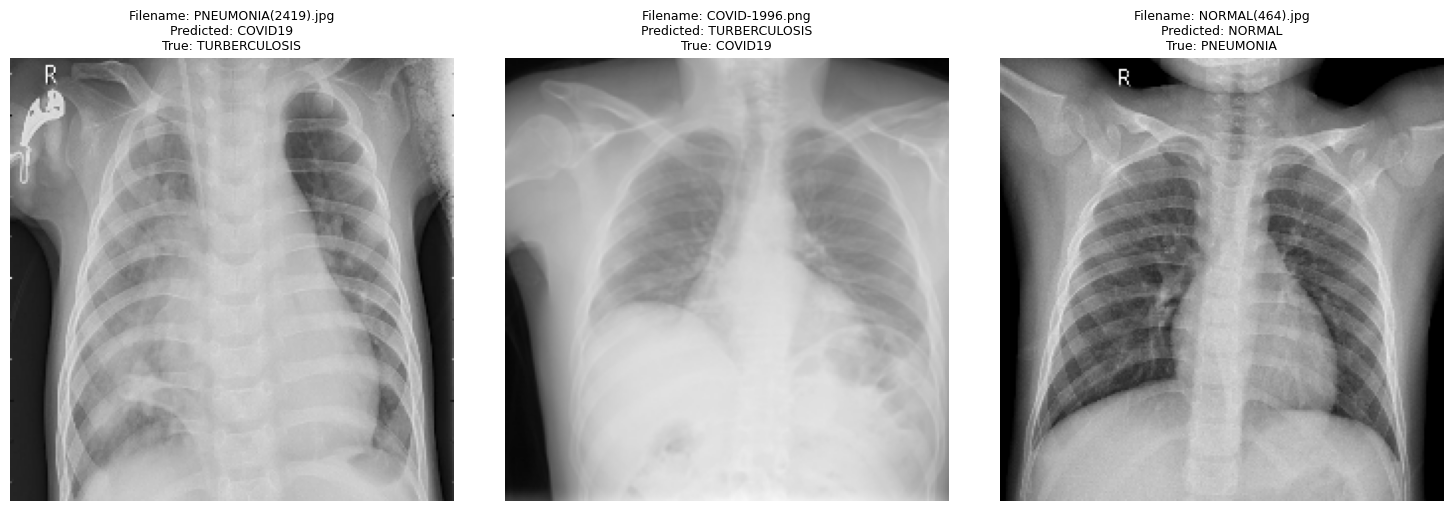

In [23]:
#Incorrectly predicted sample of images
Incorrectly_predicted_samples(val_gen_3,ypred_3,ytest_3,wrongindex)

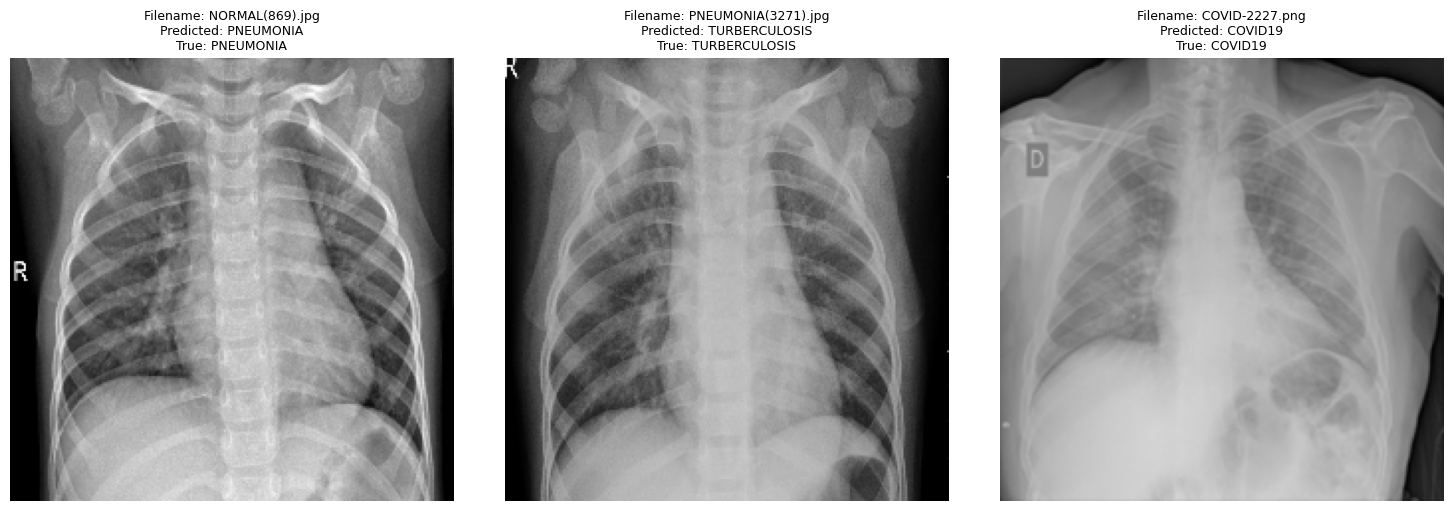

In [27]:
#correctly predicted sample of images
correctly_predicted_samples(val_gen_3,ypred_3,ytest_3,accurateindex)